In [1]:
#Import thư viện

# Data manipulation
import numpy as np #Tính toán số học
import pandas as pd #Đọc và xử lý dữ liệu

# Data visualization
import matplotlib.pyplot as plt #Trực quan hóa
import seaborn as sns #Phân tích và trực quan hóa dữ liệu

# Display setting
pd.set_option("display.max_column", None)
pd.set_option("display.max_row", 20)

print("Thư viện cài đặt thành công")

Thư viện cài đặt thành công


In [2]:
#Đọc dataset

DATA_PATH=r"C:\Users\Welcome\Desktop\BNBM\N_g_o_c\diabetes_012_health_indicators_BRFSS2015.csv"

df=pd.read_csv(DATA_PATH)

print("Dataset đọc thành công")

Dataset đọc thành công


In [3]:
#Kiểm tra 5 dòng đầu tiên
df.head()

,Diabetes_012,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,HvyAlcoholConsump,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


In [4]:
#Kiểm tra kích thước
print("Kích thước dataset: ",df.shape)
print("Số dòng: ",df.shape[0])
print("Số cột: ",df.shape[1])

Kích thước dataset:  (253680, 22)
Số dòng:  253680
Số cột:  22


In [5]:
#Kiểm tra giá trị thiếu
print(df.isnull().sum().sum())

0


Theo như nguồn dữ liệu chính thì dataset không có dữ liệu thiếu và việc kiểm tra trên đã xác nhận thông tin

In [6]:
#Kiểm tra phân phối nhãn
print(df["Diabetes_012"].value_counts())
print(df["Diabetes_012"].value_counts(normalize=True)*100)

Diabetes_012
0.0    213703
2.0     35346
1.0      4631
Name: count, dtype: int64
Diabetes_012
0.0    84.241170
2.0    13.933302
1.0     1.825528
Name: proportion, dtype: float64


Theo phân phối thì tỷ lệ của 3 lớp được chia ra:
No diabetes: 84.241170%
Pre diabetes: 13.933302%
Diabetes: 1.825528%

In [7]:
#Tách features, Target
TARGET="Diabetes_012"

#Features
x=df.drop(columns=[TARGET])

#TARGET
y=df[TARGET]

print("Tạo features và target thành công")

Tạo features và target thành công


In [8]:
#Kiểm tra x và y
print("Kích thước X: ",x.shape)
print("Kích thước Y: ",y.shape)

print("\nFeatures: ")
print(x.columns.tolist())
print("Target: ",y.value_counts())

print("\nx datatype: ")
print(x.dtypes.value_counts())
print("\ny datatype: ")
print(y.dtypes)

Kích thước X:  (253680, 21)
Kích thước Y:  (253680,)

Features: 
['HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']
Target:  Diabetes_012
0.0    213703
2.0     35346
1.0      4631
Name: count, dtype: int64

x datatype: 
float64    21
Name: count, dtype: int64

y datatype: 
float64


sau khi tách features và target, vẫn giữ nguyên được 21 cột và 253680 mẫu

In [9]:
#Chia train và temporary_set
from sklearn.model_selection import train_test_split

x_train, x_temp, y_train, y_temp= train_test_split(
    x,y,
    test_size=0.30,
    random_state=42,
    stratify=y
) 

print("Kích thước của features train: ",x_train.shape)
print("Kích thước của target train: ",y_train.shape)
print("Kích thước của features còn lại: ",x_temp.shape)
print("Kích thước của target còn lại: ",y_temp.shape)

Kích thước của features train:  (177576, 21)
Kích thước của target train:  (177576,)
Kích thước của features còn lại:  (76104, 21)
Kích thước của target còn lại:  (76104,)


Tập x_train và y_train sau khi tách 70% để giữ cho train và 30% còn lại để vào tập temp

In [10]:
#Chia temporary thành validation và test
x_val, x_test, y_val, y_test= train_test_split(
    x_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Kích thước features: ",x_val.shape,x_test.shape)
print("Kích thước target: ",y_val.shape,y_test.shape)

Kích thước features:  (38052, 21) (38052, 21)
Kích thước target:  (38052,) (38052,)


Sau khi chia đôi từ 30% của temp thành 15% của validation và test

In [11]:
#Kiểm tra kích thước
print("Train: ",x_train.shape," ",y_train.shape)
print("Validation: ",x_val.shape," ",y_val.shape)
print("Test: ",x_test.shape," ",y_test.shape)

Train:  (177576, 21)   (177576,)
Validation:  (38052, 21)   (38052,)
Test:  (38052, 21)   (38052,)


In [12]:
print("Original dataset: ",y.value_counts(normalize=True)*100)
print("\nTrain distribution: ",y_train.value_counts(normalize=True)*100)
print("\nValidation distribution: ",y_val.value_counts(normalize=True)*100)
print("\nTest distribution: ",y_test.value_counts(normalize=True)*100)

Original dataset:  Diabetes_012
0.0    84.241170
2.0    13.933302
1.0     1.825528
Name: proportion, dtype: float64

Train distribution:  Diabetes_012
0.0    84.241114
2.0    13.933189
1.0     1.825697
Name: proportion, dtype: float64

Validation distribution:  Diabetes_012
0.0    84.242615
2.0    13.933565
1.0     1.823820
Name: proportion, dtype: float64

Test distribution:  Diabetes_012
0.0    84.239987
2.0    13.933565
1.0     1.826448
Name: proportion, dtype: float64


In [13]:
#Cài đặt thư viện randomforest
from sklearn.ensemble import RandomForestClassifier


In [14]:
#Khởi tạo baseline
rf_baseline=RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

In [15]:
#Huấn luyện mô hình
rf_baseline.fit(x_train,y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [16]:
print("numbers of tree: ",len(rf_baseline.estimators_))
print("model parameters: ",rf_baseline.get_params())
print("features: ",rf_baseline.n_features_in_)

numbers of tree:  100
model parameters:  {'bootstrap': True, 'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': None, 'max_features': 'sqrt', 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 100, 'n_jobs': -1, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}
features:  21


In [17]:
#Kiểm tra trên Validation set
y_val_pred=rf_baseline.predict(x_val)
print("Actual labels: ",y_val.head(10).values)
print("Predicted: ",y_val_pred[:10])

print("x-val: ",y_val.shape)
print("Predict shape: ",y_val_pred.shape)

Actual labels:  [0. 1. 0. 2. 0. 0. 0. 0. 0. 1.]
Predicted:  [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
x-val:  (38052,)
Predict shape:  (38052,)


In [18]:
#Kiểm tra 
assert len(y_val)==len(y_val_pred)
assert set(y_val_pred).issubset({0,1,2})

In [19]:
#Đánh giá mô hình
#Accuracy
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, classification_report)
accuracy = accuracy_score(y_val, y_val_pred)
precision = precision_score(y_val, y_val_pred, average="macro", zero_division=0)
recall = recall_score(y_val, y_val_pred, average="macro", zero_division=0)
f1score = f1_score(y_val, y_val_pred, average="macro", zero_division=0)

print("Accuracy: ",accuracy)
print("Precision: ",precision)
print("Recall: ",recall)
print("F1-score: ",f1score)

print(classification_report(
    y_val,
    y_val_pred,
    labels=[0,1,2],
    target_names=[
        "No Diabetes",
        "Prediabetes",
        "Diabetes"
    ],
    zero_division=0
))


Accuracy:  0.8434773467886051
Precision:  0.4547251080854724
Recall:  0.3874269906639867
F1-score:  0.3973612548895258
              precision    recall  f1-score   support

 No Diabetes       0.86      0.97      0.91     32056
 Prediabetes       0.00      0.00      0.00       694
    Diabetes       0.50      0.19      0.28      5302

    accuracy                           0.84     38052
   macro avg       0.45      0.39      0.40     38052
weighted avg       0.80      0.84      0.81     38052



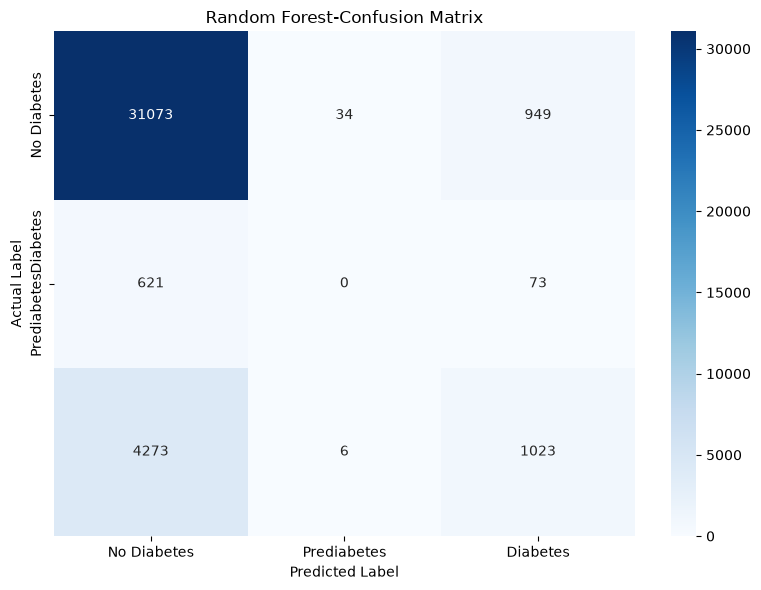

In [20]:
#Confusion matrix
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(
    y_val,
    y_val_pred,
    labels=[0,1,2]
)

plt.figure(figsize=(8,6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "No Diabetes",
        "Prediabetes",
        "Diabetes"
    ],
    yticklabels=[
        "No Diabetes",
        "Prediabetes"
        "Diabetes"
    ]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Random Forest-Confusion Matrix")
plt.tight_layout()
plt.show()

In [21]:
baseline_results= pd.DataFrame({
    "Metrics: ": [
        "Accuracy",
        "Precision Macro",
        "Recall Macro",
        "F1 Macro"
    ],
    "Score: ": [
        accuracy,
        precision,
        recall,
        f1score
    ]
})

print(baseline_results)

         Metrics:    Score: 
0         Accuracy  0.843477
1  Precision Macro  0.454725
2     Recall Macro  0.387427
3         F1 Macro  0.397361


In [22]:
#Dự đoán trên train
y_train_pred = rf_baseline.predict(x_train)
# Kiểm tra khả năng học thuộc dữ liệu của cây

In [23]:
#Tính accuracy cho 2 tập
train_accuracy= accuracy_score(
    y_train,
    y_train_pred
)
val_accuracy= accuracy_score(
    y_val,
    y_val_pred
)

print("Train-accuracy: ",train_accuracy)
print("Validation-accuracy: ",val_accuracy)

Train-accuracy:  0.9935802135423706
Validation-accuracy:  0.8434773467886051


In [24]:
#Tính macro f1 cho cả 2
train_f1=f1_score(
    y_train,
    y_train_pred,
    average="macro",
    zero_division=0
)

val_f1=f1_score(
    y_val,
    y_val_pred,
    average="macro",
    zero_division=0
)

print("Train: ",train_f1)
print("Val: ",val_f1)

Train:  0.9819743204342396
Val:  0.3973612548895258


In [25]:
accuracy_gap= train_accuracy-val_accuracy
f1_gap=train_f1-val_f1
print("Accuracy gap: ",accuracy_gap)
print("F1-score gap: ",val_f1)

Accuracy gap:  0.1501028667537655
F1-score gap:  0.3973612548895258


F1 gap lớn hơn đáng kể so với accuracy gap điều này cho thấy dấu hiệu cảnh báo chưa thể kết luận overfitting

In [26]:
# bảng tổng hợp 
table=pd.DataFrame({
    "Metrics":[
        "Accuracy",
        "Macro-f1"
    ],
    "Train":[
        train_accuracy,
        train_f1
    ],
    "Validation":[
        val_accuracy,
        val_f1
    ],
    "Gap":[
        accuracy_gap,
        f1_gap
    ]
})

print(table)

    Metrics     Train  Validation       Gap
0  Accuracy  0.993580    0.843477  0.150103
1  Macro-f1  0.981974    0.397361  0.584613


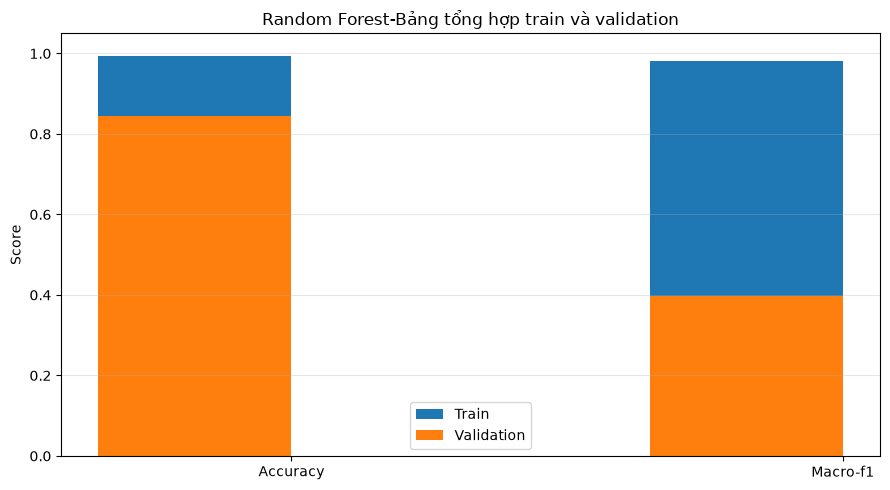

In [27]:
# trực quan hóa bảng tổng hợp
metrics=["Accuracy", "Macro-f1"]

train_score=[train_accuracy, train_f1]
val_score=[val_accuracy, val_f1]

x=np.arange(len(metrics))
width=0.35

plt.figure(figsize=(9,5))

plt.bar(
    x - width/2,
    train_score,
    width,
    label="Train"
)
plt.bar(
    x- width/2,
    val_score,
    width,
    label="Validation"
)

plt.xticks(x, metrics)
plt.ylabel("Score")
plt.title("Random Forest-Bảng tổng hợp train và validation")

plt.ylim(0, 1.05)
plt.legend()
plt.grid(axis="y",alpha=0.3)

plt.tight_layout()
plt.show()

Mô hình cho thể hiện trực quan điểm số của accuracy và macro-f1 dựa trên train và validation

In [28]:
from sklearn.model_selection import(RandomizedSearchCV, StratifiedKFold)

vì dataset quá lớn nên sẽ sử dụng randomized searchcv để hạn chế độ phức tạp và tiêu tốn tài nguyên

In [29]:
#Tạo space chứa giá trị muốn thử nghiệm
param_distributions = {
    "n_estimators": [100, 200, 300],

    "max_depth": [None, 10, 15, 20, 30],

    "min_samples_split": [2, 5, 10, 20],

    "min_samples_leaf": [1, 2, 4, 8],

    "max_features": ["sqrt", "log2", None]
}

lập ra giới hạn phạm vi cho mô hình để thử nghiệm

In [30]:
#Khởi tạo cross validation
cv_strategy = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

chia tập làm 3 để có thể sử dụng 2 tập để train và 1 tập để validation sau đó lấy trung bình của cả 3

In [31]:
#Khởi tạo randomize search
rf_search = RandomizedSearchCV(
    estimator=RandomForestClassifier(
        random_state=42,
        n_jobs=1
    ),

    param_distributions=param_distributions,

    n_iter=12,

    scoring="f1_macro",

    cv=cv_strategy,

    random_state=42,

    n_jobs=-1,

    verbose=2,

    refit=True
)

In [32]:
rf_search.fit(x_train, y_train)

Fitting 3 folds for each of 12 candidates, totalling 36 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'max_depth': [None, 10, ...], 'max_features': ['sqrt', 'log2', ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",12
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'f1_macro'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be

In [33]:
rf_tuned = rf_search.best_estimator_
print(rf_tuned.get_params())
for param, value in rf_tuned.get_params().items():
    print(f"{param}: {value}") 


{'bootstrap': True, 'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': 15, 'max_features': None, 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 10, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 100, 'n_jobs': 1, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}
bootstrap: True
ccp_alpha: 0.0
class_weight: None
criterion: gini
max_depth: 15
max_features: None
max_leaf_nodes: None
max_samples: None
min_impurity_decrease: 0.0
min_samples_leaf: 1
min_samples_split: 10
min_weight_fraction_leaf: 0.0
monotonic_cst: None
n_estimators: 100
n_jobs: 1
oob_score: False
random_state: 42
verbose: 0
warm_start: False


lưu mô hình tốt nhất 
giờ ta có 2 mô hình rf_baseline và rf_tunned

In [34]:
y_val_pred_tuned = rf_tuned.predict(x_val)

chạy lại trên validation

In [35]:
# Tính các metrics sau khi chạy qua mô hình tốt nhất
tunned_accuracy= accuracy_score(
    y_val,
    y_val_pred_tuned
)

tunned_precision= precision_score(
    y_val,
    y_val_pred_tuned,
    average="macro",
    zero_division=0
)

tunned_recall= recall_score(
    y_val,
    y_val_pred_tuned,
    average="macro",
    zero_division=0
)

tunned_f1= f1_score(
    y_val,
    y_val_pred_tuned,
    average="macro",
    zero_division=0
)

print("accuracy: ",tunned_accuracy)
print("precision: ",tunned_precision)
print("recall: ",tunned_recall)
print("f1: ",tunned_f1)

accuracy:  0.8495217071376012
precision:  0.47292857566873564
recall:  0.3875623904238248
f1:  0.3982112423678086


In [36]:
# So sánh hai mô hình baseline và tunned
comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision Macro",
        "Recall Macro",
        "F1 Macro"
    ],

    "Baseline": [
        accuracy_score(y_val, y_val_pred),
        precision_score(
            y_val, y_val_pred,
            average="macro",
            zero_division=0
        ),
        recall_score(
            y_val, y_val_pred,
            average="macro",
            zero_division=0
        ),
        f1_score(
            y_val, y_val_pred,
            average="macro",
            zero_division=0
        )
    ],

    "Tuned": [
        tunned_accuracy,
        tunned_precision,
        tunned_recall,
        tunned_f1
    ]
})

comparison["Improvement"] = (
    comparison["Tuned"] - comparison["Baseline"]
)

print(comparison)

            Metric  Baseline     Tuned  Improvement
0         Accuracy  0.843477  0.849522     0.006044
1  Precision Macro  0.454725  0.472929     0.018203
2     Recall Macro  0.387427  0.387562     0.000135
3         F1 Macro  0.397361  0.398211     0.000850


In [37]:
# So sánh lại train và tuuned
y_train_pred_tuned = rf_tuned.predict(x_train)

train_f1_tuned = f1_score(
    y_train,
    y_train_pred_tuned,
    average="macro",
    zero_division=0
)

val_f1_tuned = f1_score(
    y_val,
    y_val_pred_tuned,
    average="macro",
    zero_division=0
)

print("Train Macro F1:", train_f1_tuned)
print("Validation Macro F1:", val_f1_tuned)

print(
    "Generalization Gap:",
    train_f1_tuned - val_f1_tuned
)

Train Macro F1: 0.4856630530177674
Validation Macro F1: 0.3982112423678086
Generalization Gap: 0.08745181064995883


In [38]:
# Lấy features importance
feature_importance = pd.DataFrame({
    "Feature": x_train.columns,
    "Importance": rf_tuned.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance.head(10)

,Feature,Importance
0,HighBP,0.167435
3,BMI,0.145980
13,GenHlth,0.142306
18,Age,0.087923
20,Income,0.069562
15,PhysHlth,0.068384
14,MentHlth,0.056971
19,Education,0.048979
1,HighChol,0.036139
17,Sex,0.019392


feature có tỷ lệ quan trọng cao nhất là HighBP(cao huyết áp)

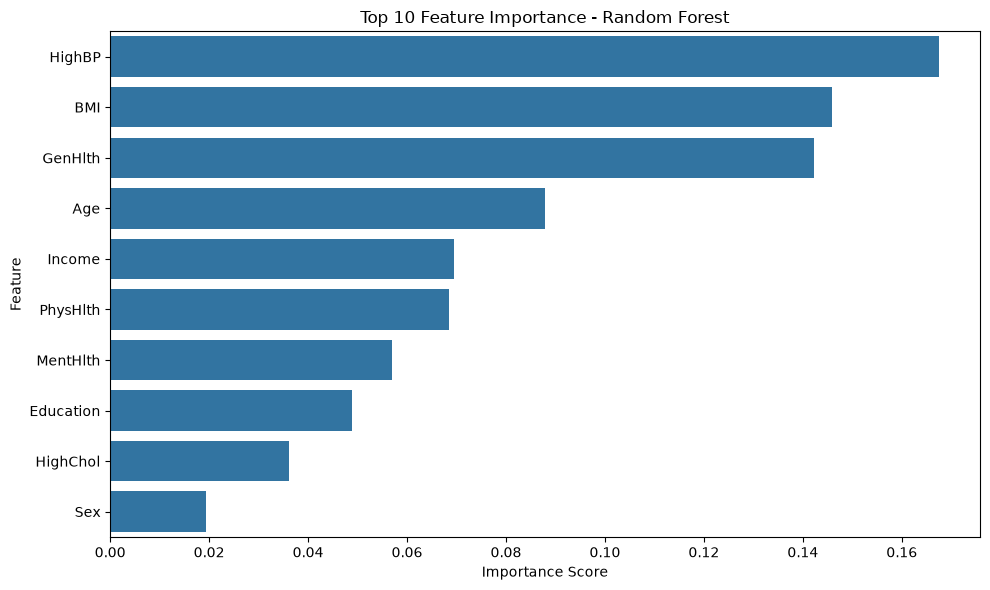

In [39]:
# Trực quan hóa top 10 feature quan trọng nhất
top_10_features = feature_importance.head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_10_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Feature Importance - Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

ta thấy HighBP cao nhất vậy HighBP là feature góp phần nhiều nhất vào việc quyết định kết quả

In [40]:
# xem xét tầm ảnh hưởng của features với điểm số 
# cài đặt thư viện 
from sklearn.inspection import permutation_importance

In [41]:
# tính permutation hoán vị các giá trị giữa các mẫu đã qua mô hình tối ưu
perm_result = permutation_importance(
    estimator=rf_tuned,
    X=x_val,
    y=y_val,
    scoring="f1_macro",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

In [42]:
# Tạo bảng kết quả 
permutation_df = pd.DataFrame({
    "Feature": x_val.columns,
    "Importance_Mean": perm_result.importances_mean,
    "Importance_Std": perm_result.importances_std
})

permutation_df = permutation_df.sort_values(
    by="Importance_Mean",
    ascending=False
)

permutation_df.head(10)

,Feature,Importance_Mean,Importance_Std
3,BMI,0.040723,0.001559
0,HighBP,0.027526,0.001372
13,GenHlth,0.023547,0.000897
1,HighChol,0.019284,0.000741
18,Age,0.012692,0.000825
20,Income,0.005709,0.000539
6,HeartDiseaseorAttack,0.004805,0.000351
14,MentHlth,0.002497,0.000688
10,HvyAlcoholConsump,0.001979,0.000335
17,Sex,0.001181,0.000387


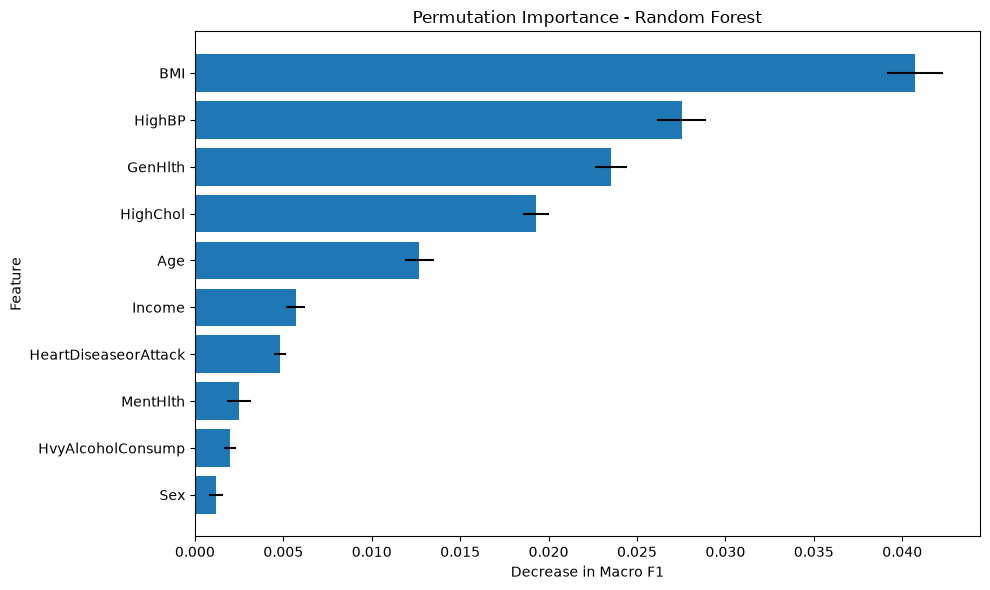

In [43]:
# vẽ biểu đồ
top_10_perm = permutation_df.head(10).sort_values(
    by="Importance_Mean",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_10_perm["Feature"],
    top_10_perm["Importance_Mean"],
    xerr=top_10_perm["Importance_Std"]
)

plt.title("Permutation Importance - Random Forest")
plt.xlabel("Decrease in Macro F1")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

sau khi chạy qua permutation thì feature có tỷ lệ quan trọng cao nhất là BMI thay vì HighBP (chỉ số khối của cơ thể > cao huyết áp)

In [44]:
# chọn tuned làm final model
from sklearn.base import clone

final_model = clone(rf_tuned)

vì khi so sánh ở bảng trên t thấy tuned có sự tăng nhưng không quá nhiều nhưng vẫn là dấu hiệu cho thấy mô hình có sự cân bằng tốt hơn giữa precision và recall trên các lớp

In [45]:
# gộp train và validation 
x_train_val = pd.concat(
    [x_train, x_val],
    axis=0
)

y_train_val = pd.concat(
    [y_train, y_val],
    axis=0
)

print("x_train_val:", x_train_val.shape)
print("y_train_val:", y_train_val.shape)

x_train_val: (215628, 21)
y_train_val: (215628,)


In [46]:
#Huấn luyện model
final_model.fit(
    x_train_val,
    y_train_val
)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",15
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",10
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y_

In [47]:
# Dự đoán trên test
y_test_pred = final_model.predict(x_test)

In [48]:
test_accuracy = accuracy_score(
    y_test,
    y_test_pred
)

test_precision = precision_score(
    y_test,
    y_test_pred,
    average="macro",
    zero_division=0
)

test_recall = recall_score(
    y_test,
    y_test_pred,
    average="macro",
    zero_division=0
)

test_f1 = f1_score(
    y_test,
    y_test_pred,
    average="macro",
    zero_division=0
)

print("Test Accuracy:", test_accuracy)
print("Test Macro Precision:", test_precision)
print("Test Macro Recall:", test_recall)
print("Test Macro F1:", test_f1)

Test Accuracy: 0.8480500367917586
Test Macro Precision: 0.46754124862324503
Test Macro Recall: 0.38956128407097984
Test Macro F1: 0.4005013848756514


In [49]:
# xem xét từng lớp
print(
    classification_report(
        y_test,
        y_test_pred,
        labels=[0, 1, 2],
        target_names=[
            "No Diabetes",
            "Prediabetes",
            "Diabetes"
        ],
        zero_division=0
    )
)

              precision    recall  f1-score   support

 No Diabetes       0.86      0.97      0.92     32055
 Prediabetes       0.00      0.00      0.00       695
    Diabetes       0.54      0.19      0.29      5302

    accuracy                           0.85     38052
   macro avg       0.47      0.39      0.40     38052
weighted avg       0.80      0.85      0.81     38052



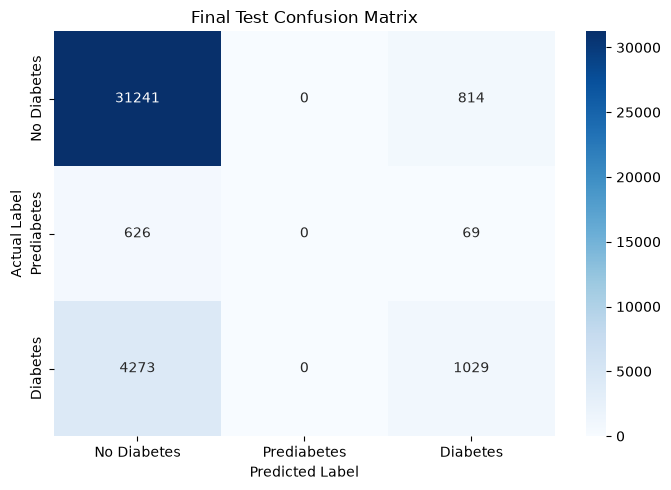

In [50]:
# confusion matrix
cm = confusion_matrix(
    y_test,
    y_test_pred,
    labels=[0, 1, 2]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "No Diabetes",
        "Prediabetes",
        "Diabetes"
    ],
    yticklabels=[
        "No Diabetes",
        "Prediabetes",
        "Diabetes"
    ]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Final Test Confusion Matrix")

plt.tight_layout()
plt.show()

In [51]:
# so sánh validation và final
final_comparison = pd.DataFrame({
    "Dataset": ["Validation", "Test"],
    "Accuracy": [
        accuracy_score(y_val, final_model.predict(x_val)),
        test_accuracy
    ],
    "Macro_F1": [
        f1_score(
            y_val,
            final_model.predict(x_val),
            average="macro",
            zero_division=0
        ),
        test_f1
    ]
})

final_comparison

,Dataset,Accuracy,Macro_F1
0,Validation,0.883738,0.481826
1,Test,0.848050,0.400501
